In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [20]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

вычитали файл в переменную, за индекс взяли колонку PassengerId

In [21]:
train_data = pd.read_csv("./dataset/train.csv", index_col='PassengerId')

вывели первые записи, чтобы визуально оценить таблицу

In [22]:
print(train_data.head())

             Survived  Pclass                                               Name     Sex   Age  SibSp  Parch            Ticket     Fare Cabin Embarked
PassengerId                                                                                                                                           
1                   0       3                            Braund, Mr. Owen Harris    male  22.0      1      0         A/5 21171   7.2500   NaN        S
2                   1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1      0          PC 17599  71.2833   C85        C
3                   1       3                             Heikkinen, Miss. Laina  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN        S
4                   1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0            113803  53.1000  C123        S
5                   0       3                           Allen, Mr. William Henry    male  35.0

информация о количестве ненулевых признаков в каждой колонке и типе данных

In [23]:
print(train_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB
None


видим, что в колонке пола нет пропусков и два возможных значения, можно перейти от строчного к числовому представлению

In [24]:
# Преобразование колонки пола из male, female в 1, 0
def transform_sex_to_int(sex_column: pd.Series) -> pd.Series:
    return (sex_column == 'male').astype(int)

train_data['Sex'] = transform_sex_to_int(train_data['Sex'])

разобьем столбцы по типам

In [25]:
columns_int64 = ['Survived', 'Pclass', 'Sex', 'SibSp', 'Parch']
columns_float64 = ['Age', 'Fare']
columns_str = ['Name', 'Ticket', 'Cabin', 'Embarked']

по каждому целочисленному столбцу можно посмотреть возможные значения и их частоту

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


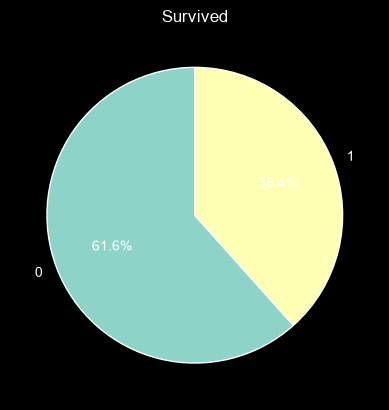

Pclass
3    0.551066
1    0.242424
2    0.206510
Name: proportion, dtype: float64


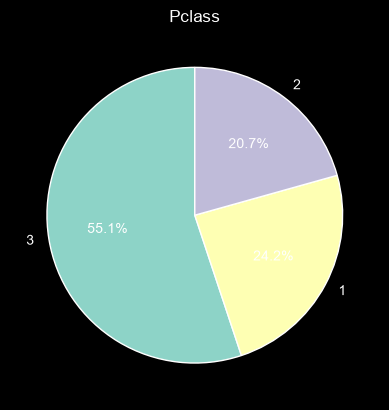

Sex
1    0.647587
0    0.352413
Name: proportion, dtype: float64


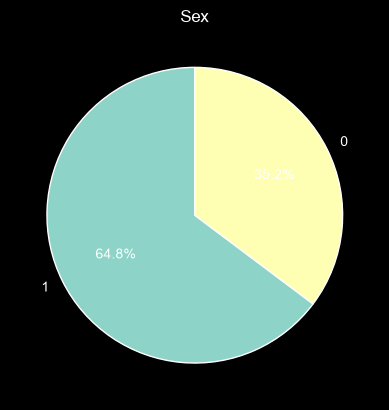

SibSp
0    0.682379
1    0.234568
2    0.031425
4    0.020202
3    0.017957
8    0.007856
5    0.005612
Name: proportion, dtype: float64


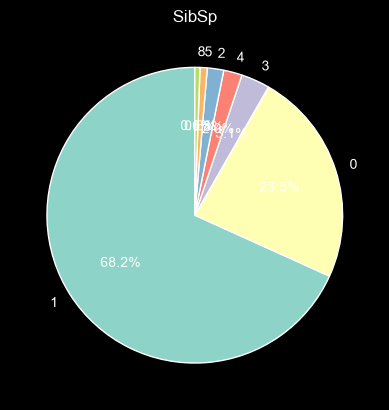

Parch
0    0.760943
1    0.132435
2    0.089787
5    0.005612
3    0.005612
4    0.004489
6    0.001122
Name: proportion, dtype: float64


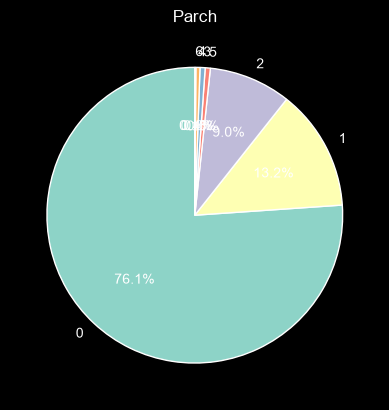

In [26]:
for column in columns_int64:
    print(train_data[column].value_counts(normalize=True))
    # те же данные в виде гистограммы
    plt.pie(train_data[column].value_counts(), labels=train_data[column].unique(), autopct='%1.1f%%', startangle=90)
    plt.title(column)
    plt.show()

по каждому вещественному столбцу можно посмотреть возможные значения и их частоту (только на графике, потому что все значения уникальны)

Age
(16.336, 24.294]    0.247899
(24.294, 32.252]    0.236695
(32.252, 40.21]     0.165266
(40.21, 48.168]     0.098039
(0.34, 8.378]       0.075630
(8.378, 16.336]     0.064426
(48.168, 56.126]    0.063025
(56.126, 64.084]    0.033613
(64.084, 72.042]    0.012605
(72.042, 80.0]      0.002801
Name: proportion, dtype: float64


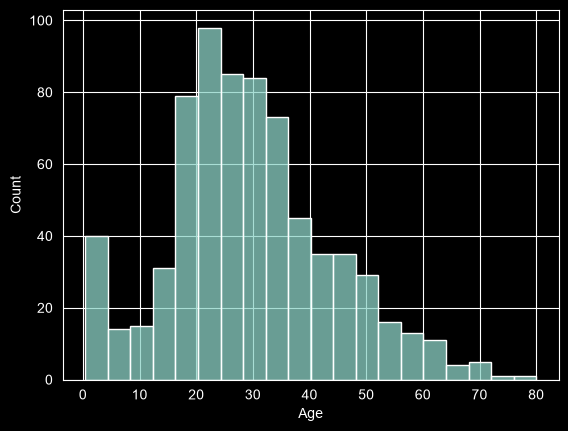

Fare
(-0.512, 51.233]      0.821549
(51.233, 102.466]     0.118967
(102.466, 153.699]    0.034792
(204.932, 256.165]    0.012346
(256.165, 307.398]    0.006734
(461.096, 512.329]    0.003367
(153.699, 204.932]    0.002245
(307.398, 358.63]     0.000000
(358.63, 409.863]     0.000000
(409.863, 461.096]    0.000000
Name: proportion, dtype: float64


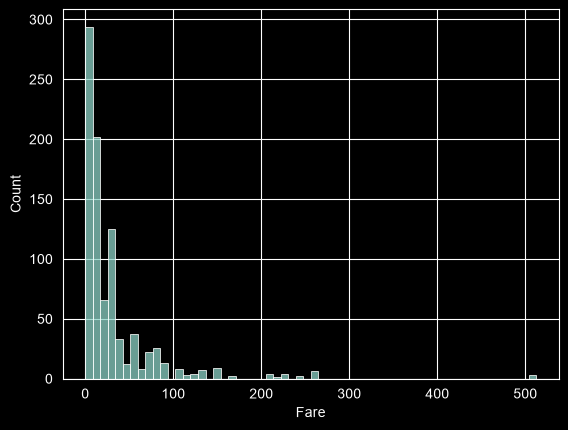

In [27]:
for column in columns_float64:
    print(pd.cut(train_data[column], 10).value_counts(normalize=True))
    sns.histplot(train_data[column])
    plt.show()

по графику можем заметить выброс по стоимости билета Fare и подобрать для него значение 95 процентиля

In [28]:
print(train_data['Fare'].quantile(0.95))

112.07915


или построим боксплоты для поиска выбросов

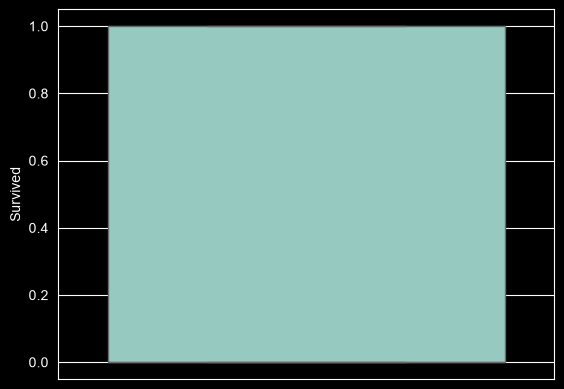

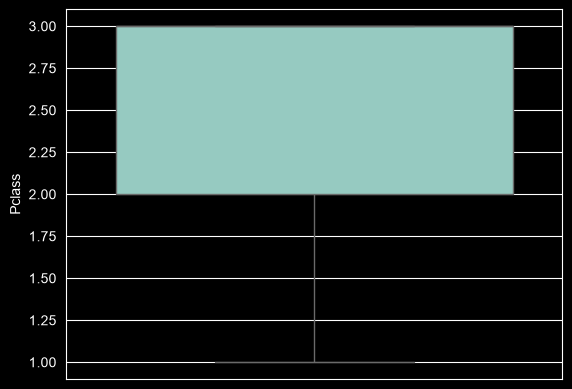

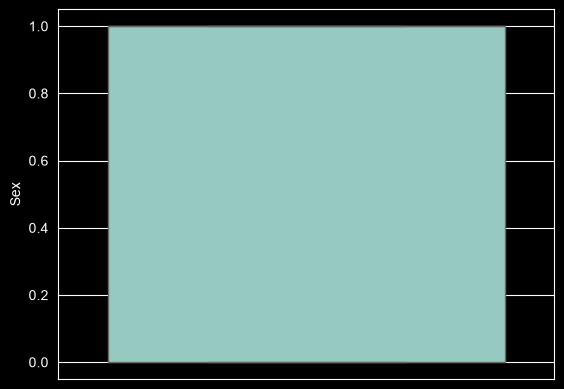

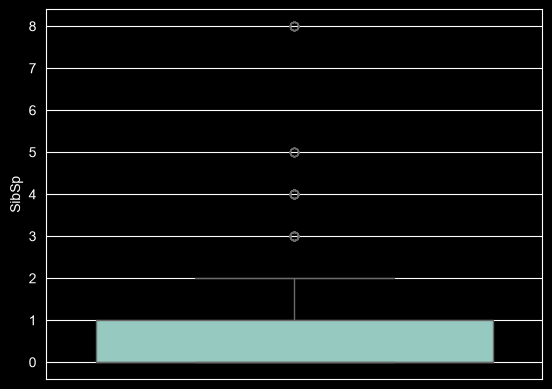

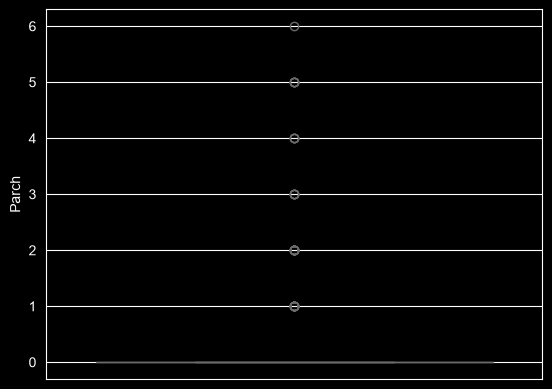

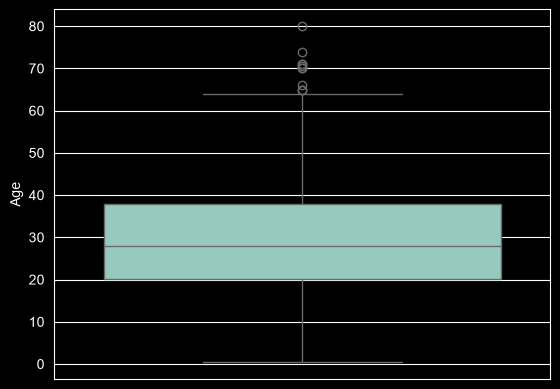

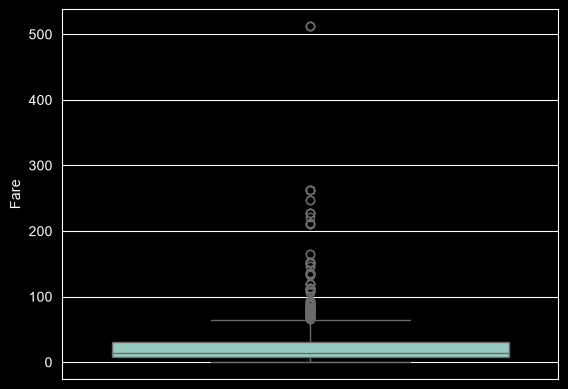

In [29]:
for column in columns_int64 + columns_float64:
    sns.boxplot(train_data[column])
    plt.show()

для численных типов можно вывести статистики по столбцам (столбцы выбираются автоматически в виде таблицы

In [30]:
print(train_data.describe())

         Survived      Pclass         Sex         Age       SibSp       Parch        Fare
count  891.000000  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642    0.647587   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071    0.477990   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000    0.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000    1.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000    1.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000    1.000000   80.000000    8.000000    6.000000  512.329200


для числовых типов можно найти корреляцию

In [31]:
print(train_data[columns_int64 + columns_float64].corr())

          Survived    Pclass       Sex     SibSp     Parch       Age      Fare
Survived  1.000000 -0.338481 -0.543351 -0.035322  0.081629 -0.077221  0.257307
Pclass   -0.338481  1.000000  0.131900  0.083081  0.018443 -0.369226 -0.549500
Sex      -0.543351  0.131900  1.000000 -0.114631 -0.245489  0.093254 -0.182333
SibSp    -0.035322  0.083081 -0.114631  1.000000  0.414838 -0.308247  0.159651
Parch     0.081629  0.018443 -0.245489  0.414838  1.000000 -0.189119  0.216225
Age      -0.077221 -0.369226  0.093254 -0.308247 -0.189119  1.000000  0.096067
Fare      0.257307 -0.549500 -0.182333  0.159651  0.216225  0.096067  1.000000


значимая корреляция выживания с полом, классом и стоимостью билета. кроме того класс коррелирует со стоимостью билета, число родителей с полом и числом братьев, возраст с классом, братьями и родителями

та же корреляция в виде тепловой карты

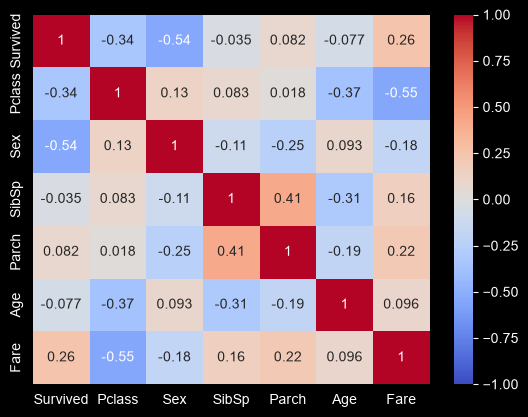

In [32]:
sns.heatmap(train_data[columns_int64 + columns_float64].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

построим график зависимости выживаемости от других числовых признаков. Наблюдения получились интересными для числа супруг/братьев и детей/родителей

          count  mean  median
Survived                     
0           549   0.0     0.0
1           342   1.0     1.0


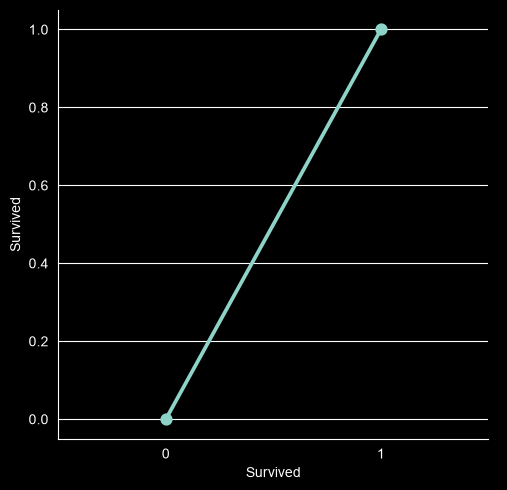

        count      mean  median
Pclass                         
1         216  0.629630     1.0
2         184  0.472826     0.0
3         491  0.242363     0.0


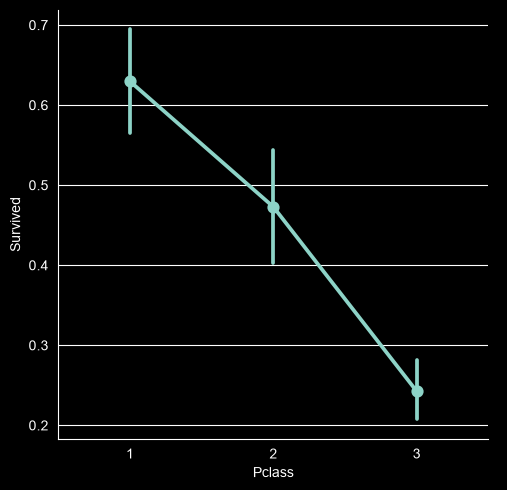

     count      mean  median
Sex                         
0      314  0.742038     1.0
1      577  0.188908     0.0


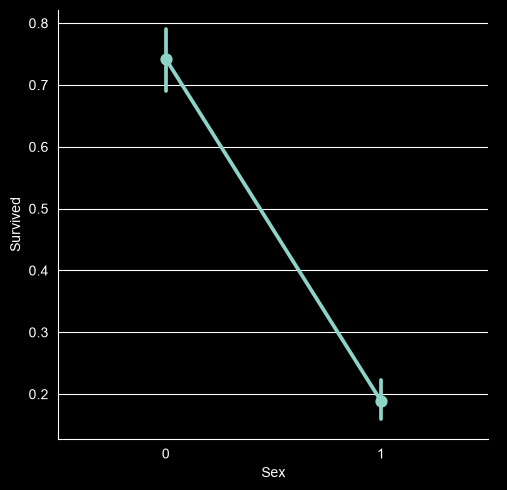

       count      mean  median
SibSp                         
0        608  0.345395     0.0
1        209  0.535885     1.0
2         28  0.464286     0.0
3         16  0.250000     0.0
4         18  0.166667     0.0
5          5  0.000000     0.0
8          7  0.000000     0.0


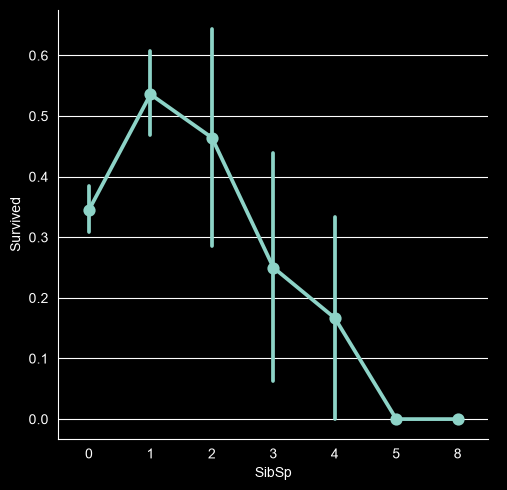

       count      mean  median
Parch                         
0        678  0.343658     0.0
1        118  0.550847     1.0
2         80  0.500000     0.5
3          5  0.600000     1.0
4          4  0.000000     0.0
5          5  0.200000     0.0
6          1  0.000000     0.0


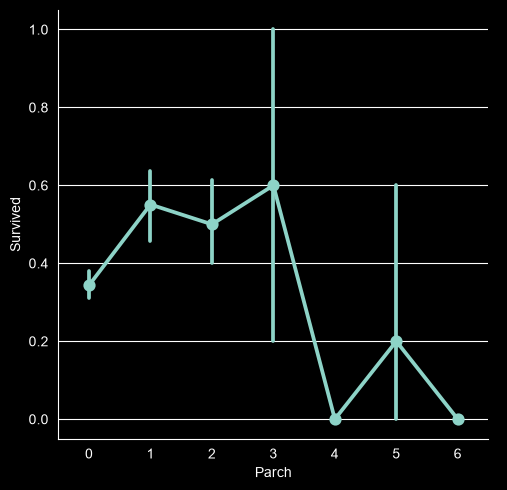

       count  mean  median
Age                       
0.42       1   1.0     1.0
0.67       1   1.0     1.0
0.75       2   1.0     1.0
0.83       2   1.0     1.0
0.92       1   1.0     1.0
...      ...   ...     ...
70.00      2   0.0     0.0
70.50      1   0.0     0.0
71.00      2   0.0     0.0
74.00      1   0.0     0.0
80.00      1   1.0     1.0

[88 rows x 3 columns]


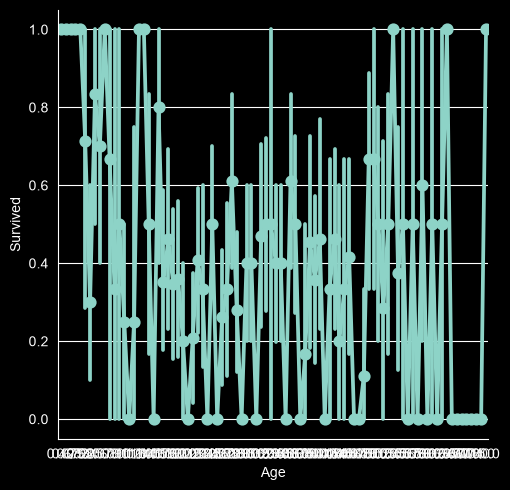

          count      mean  median
Fare                             
0.0000       15  0.066667     0.0
4.0125        1  0.000000     0.0
5.0000        1  0.000000     0.0
6.2375        1  0.000000     0.0
6.4375        1  0.000000     0.0
...         ...       ...     ...
227.5250      4  0.750000     1.0
247.5208      2  0.500000     0.5
262.3750      2  1.000000     1.0
263.0000      4  0.500000     0.5
512.3292      3  1.000000     1.0

[248 rows x 3 columns]


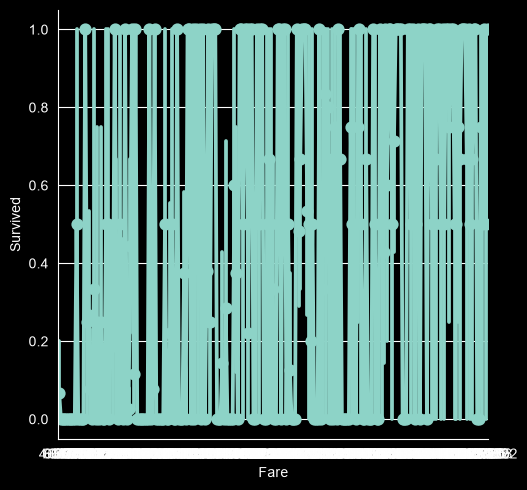

In [33]:
for column in columns_int64 + columns_float64:
    print(train_data.groupby(column)['Survived'].agg(['count', 'mean', 'median']))
    sns.catplot(x=column, y='Survived', data=train_data, kind="point")
    plt.show()

дополнительно нужны графики связи признаков с возрастом (чтобы понять, как лучше заменять пропуски возраста)
построим график зависимости возраста от других числовых признаков, чтобы понять принцип заполнения пропусков

          count       mean  median
Survived                          
0           424  30.626179    28.0
1           290  28.343690    28.0


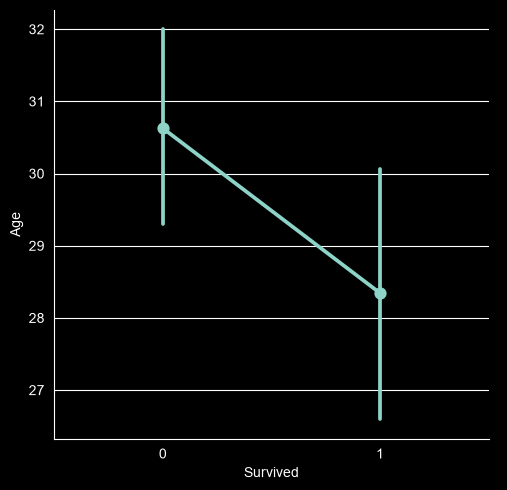

        count       mean  median
Pclass                          
1         186  38.233441    37.0
2         173  29.877630    29.0
3         355  25.140620    24.0


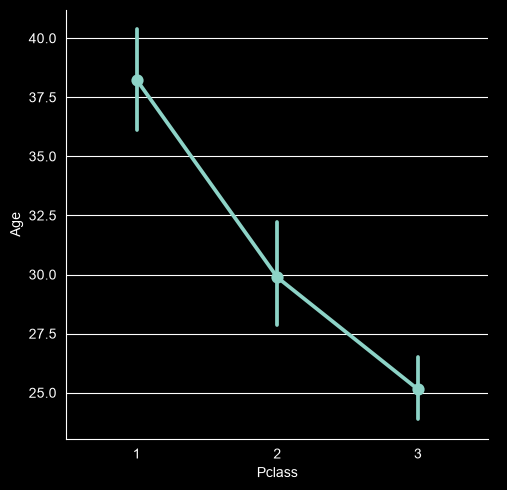

     count       mean  median
Sex                          
0      261  27.915709    27.0
1      453  30.726645    29.0


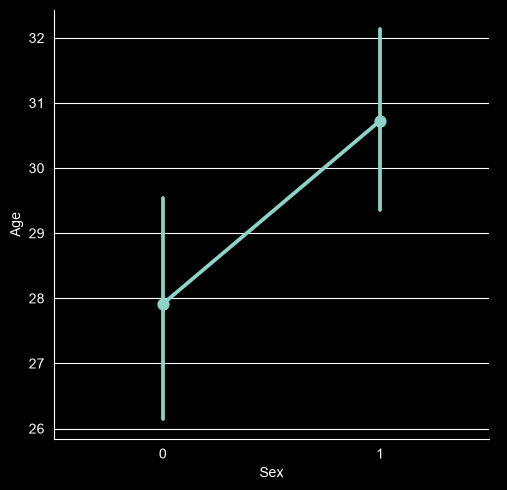

       count       mean  median
SibSp                          
0        471  31.397558    29.0
1        183  30.089727    30.0
2         25  22.620000    23.0
3         12  13.916667     9.5
4         18   7.055556     6.5
5          5  10.200000    11.0
8          0        NaN     NaN


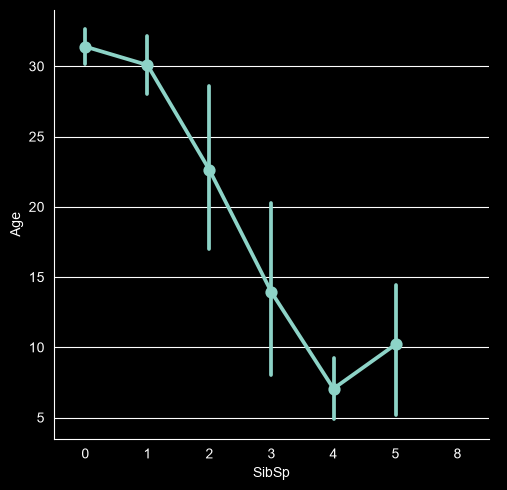

       count       mean  median
Parch                          
0        521  32.178503    30.0
1        110  24.422000    23.0
2         68  17.216912    16.5
3          5  33.200000    24.0
4          4  44.500000    42.5
5          5  39.200000    39.0
6          1  43.000000    43.0


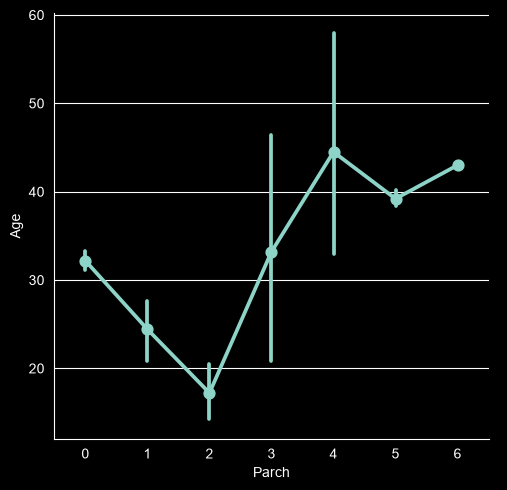

       count   mean  median
Age                        
0.42       1   0.42    0.42
0.67       1   0.67    0.67
0.75       2   0.75    0.75
0.83       2   0.83    0.83
0.92       1   0.92    0.92
...      ...    ...     ...
70.00      2  70.00   70.00
70.50      1  70.50   70.50
71.00      2  71.00   71.00
74.00      1  74.00   74.00
80.00      1  80.00   80.00

[88 rows x 3 columns]


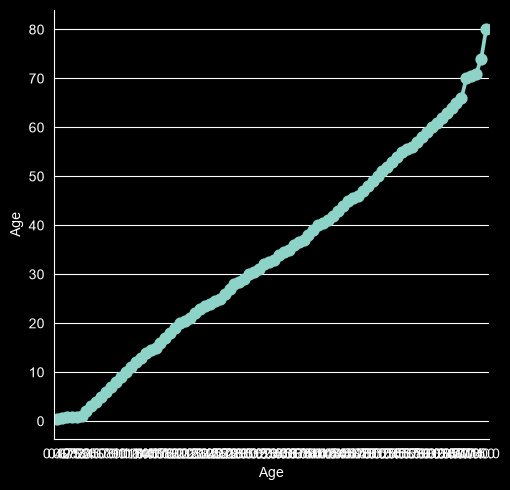

          count       mean  median
Fare                              
0.0000        7  35.142857    38.0
4.0125        1  20.000000    20.0
5.0000        1  33.000000    33.0
6.2375        1  61.000000    61.0
6.4375        1  34.500000    34.5
...         ...        ...     ...
227.5250      3  32.666667    38.0
247.5208      2  37.000000    37.0
262.3750      2  19.500000    19.5
263.0000      4  32.500000    23.5
512.3292      3  35.333333    35.0

[248 rows x 3 columns]


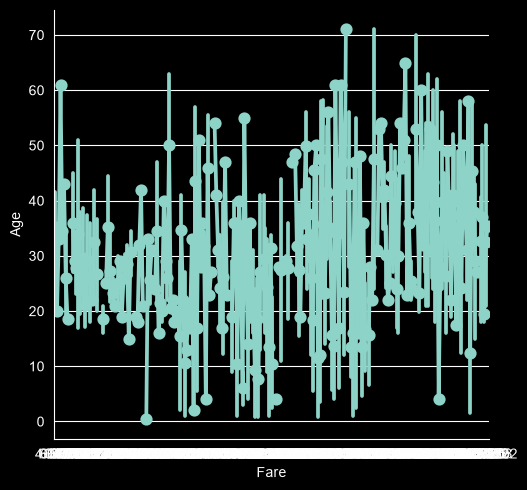

In [34]:
for column in columns_int64 + columns_float64:
    print(train_data.groupby(column)['Age'].agg(['count', 'mean', 'median']))
    sns.catplot(x=column, y='Age', data=train_data, kind="point")
    plt.show()

можно смотреть зависимость с категориальными признаками. видно, что тут не случайное распределение

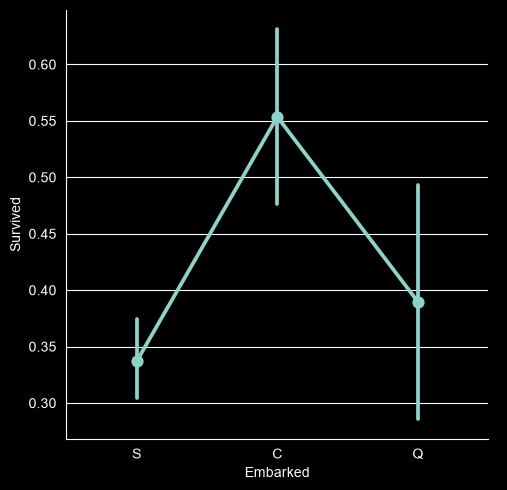

In [35]:
sns.catplot(x='Embarked', y='Survived', data=train_data, kind="point")
plt.show()

можно смотреть связь статистики по нескольким параметрам. Например, здесь видно, что большинство детей выживает, а стариков нет

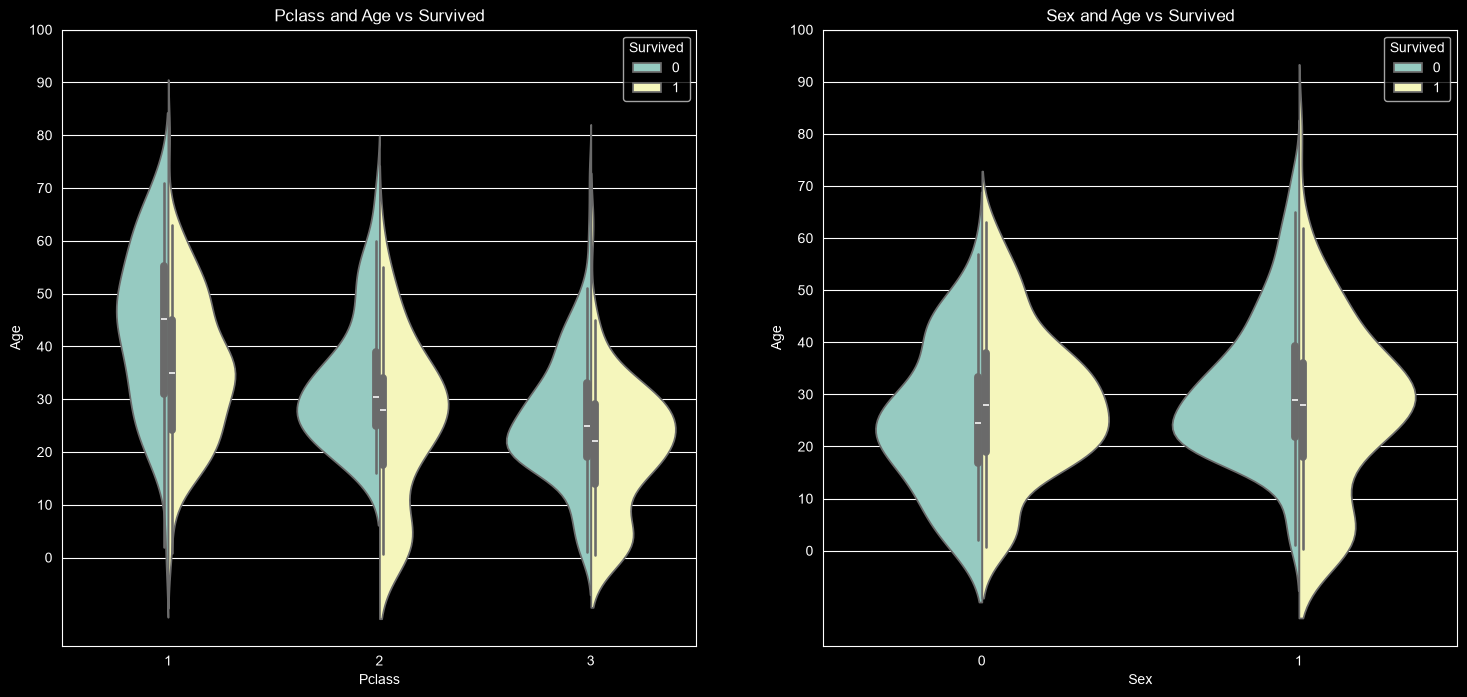

In [36]:
f, ax = plt.subplots(1, 2, figsize=(18, 8))
sns.violinplot(x="Pclass", y="Age", hue="Survived", data=train_data, split=True, ax=ax[0])
ax[0].set_title('Pclass and Age vs Survived')
ax[0].set_yticks(range(0, 110, 10))
sns.violinplot(x="Sex", y="Age", hue="Survived", data=train_data, split=True, ax=ax[1])
ax[1].set_title('Sex and Age vs Survived')
ax[1].set_yticks(range(0, 110, 10))
plt.show()